# 04. CNN architectures trained from scratch

Question: *what makes a CNN work on NEU: depth through repetition (VGG), residual links (ResNet), dense
feature reuse (DenseNet), or efficient depthwise separable convolutions (MobileNet)?*

All networks are implemented from scratch (`idefect.models`) and trained with the custom CNN's recipe
unchanged: the same group-aware split, augmentation, Adam, cosine schedule, 150 epochs, checkpoint by
validation macro-F1, five seeds. Test scores below are means over seeds; the seed kept as the saved
model is chosen on validation, never on test.

In [1]:
import csv, json, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from idefect.config import load_config
from idefect.models.registry import display_name

cfg = load_config("configs/neu_baseline.yaml")
RES = Path(cfg.output.results_dir)
FIG = Path(cfg.output.figures_dir)


def show(path):
    # Display a saved figure at full resolution.
    display(Image(filename=str(path)))


def seeds_table(stems):
    rows = []
    for stem in stems:
        m = json.loads((RES / f"{stem}_metrics.json").read_text())
        s = m["seed_summary"]
        rows.append({"model": m["display_name"], "trained params": m["n_params"],
                     "total params": m.get("n_params_total", m["n_params"]),
                     "test macro-F1 mean": s["test_macro_f1"]["mean"], "test std": s["test_macro_f1"]["std"],
                     "test min": s["test_macro_f1"]["min"], "test max": s["test_macro_f1"]["max"],
                     "val macro-F1 mean": s["val_macro_f1"]["mean"],
                     "seconds per seed": s["train_time_sec"]["mean"]})
    return pd.DataFrame(rows).set_index("model").round(4)

seeds_table(['custom_cnn', 'vgg', 'resnet', 'densenet', 'mobilenet'])

,trained params,total params,test macro-F1 mean,test std,test min,test max,val macro-F1 mean,seconds per seed
model,,,,,,,,
Custom CNN,93670,93670,0.9881,0.0055,0.9814,0.9963,0.9789,76.848
VGG-style CNN,1174182,1174182,0.9940,0.0033,0.9888,0.9963,0.9912,193.932
ResNet-18 (scratch),2796006,2796006,0.9903,0.0020,0.9888,0.9925,0.9839,527.214
DenseNet-BC (scratch),773638,773638,0.9866,0.0117,0.9739,0.9963,0.9898,490.122
MobileNetV2 (scratch),2230982,2230982,0.9591,0.0156,0.9330,0.9738,0.9737,128.018


Findings:

* **Depth through repetition works; the fancier blocks do not add more.** VGG-style is the best scratch
  network (0.9940 +- 0.0033), but the custom CNN, VGG, ResNet-18 and DenseNet-BC lie within about two
  test images of each other (one image is about 0.0037 macro-F1).
* **MobileNetV2 from scratch is the weakest and least stable** (0.9591 +- 0.0156). The architecture is
  not the problem: with ImageNet weights the same network reaches 0.9970 (notebook 05).
* **DenseNet-BC is the least stable of the rest** (seeds from 0.9739 to 0.9963).

## Training curves of the best scratch network (VGG-style, kept seed)

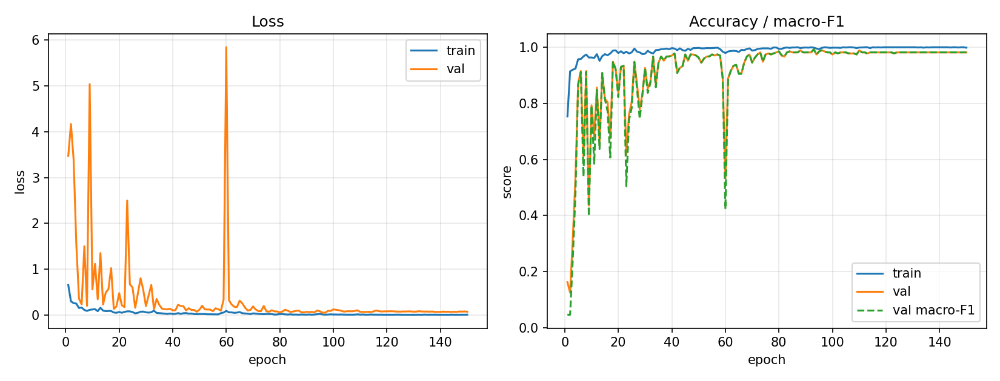

In [2]:
show(FIG / "vgg_training_curves.png")

## Which test images do they get wrong? (kept seed of each model)

In [3]:
rows = []
for stem in ['custom_cnn', 'vgg', 'resnet', 'densenet', 'mobilenet']:
    preds = list(csv.DictReader(open(RES / f"{stem}_test_predictions.csv")))
    wrong = [f"{Path(r['path']).stem} ({r['true']} as {r['pred']})" for r in preds if r["correct"] == "0"]
    rows.append({"model": display_name(stem), "errors": len(wrong), "images": ", ".join(wrong)})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows).set_index("model")

,errors,images
model,,
Custom CNN,3,"Sc_44 (scratches as inclusion), PS_282 (pitted_surface as inclusion), PS_198 (pitted_surface as inclusion)"
VGG-style CNN,3,"Sc_44 (scratches as inclusion), RS_11 (rolled-in_scale as pitted_surface), Sc_95 (scratches as inclusion)"
ResNet-18 (scratch),3,"Sc_44 (scratches as inclusion), Sc_60 (scratches as inclusion), Sc_89 (scratches as inclusion)"
DenseNet-BC (scratch),1,Sc_44 (scratches as inclusion)
MobileNetV2 (scratch),7,"In_254 (inclusion as pitted_surface), Sc_44 (scratches as inclusion), In_249 (inclusion as pitted_surface), PS_282 (pitted_surface as inclusion), Sc_89 (scratches as inclusion), Sc_87 (scratches a..."


Every scratch CNN misclassifies `Sc_44.bmp` (a very faint, broad scratch) as inclusion, in every
seed (0 of 25 runs), like every classical model in notebook 03.

## Where they look: Grad-CAM

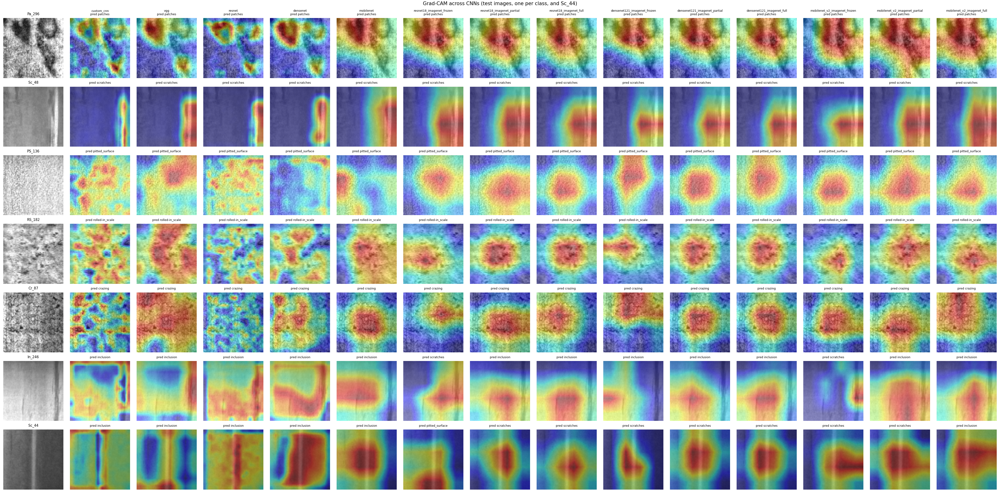

In [4]:
show(FIG / "cnn" / "gradcam_comparison.png")

* The scratch CNNs with fine final maps (16x16 for the custom CNN, ResNet-18 and DenseNet-BC, 8x8 for
  VGG at 128 px) trace the defect: the scratch line, the edges of dark patches, the crazing network.
* Networks that downsample 32 times (the ImageNet backbones and the scratch MobileNetV2) end in a 4x4
  map and produce coarse blobs.
* Grad-CAM does not explain `Sc_44.bmp`: its band covers 4 pixel columns (3 percent of the image) and
  every model puts 2 to 6 percent of its map there, whichever class it predicts.

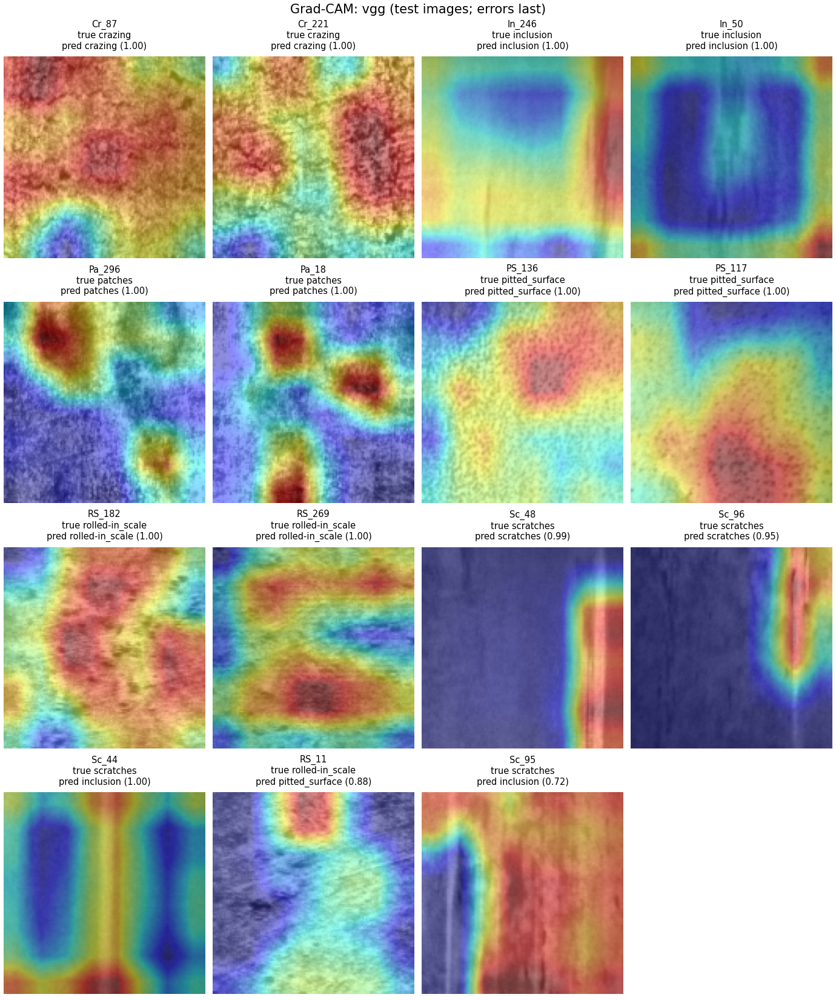

In [5]:
show(FIG / "cnn" / "gradcam_vgg.png")

## Sensitivity: input resolution and CLAHE (validation split only, 3 seeds)

In [6]:
s = json.loads((RES / "cnn_studies" / "cnn_sensitivity.json").read_text())
df = pd.DataFrame(s["summary"])
df["model"] = [display_name(a, f) for a, f in zip(df["arch"], df["finetune"])]
df.pivot_table(index="model", columns="variant", values="val_macro_f1_mean", sort=False).round(4)

variant,64 px,128 px,200 px,no CLAHE,CLAHE
model,,,,,
Custom CNN,0.9878,0.9794,0.9721,0.9805,0.9794
VGG-style CNN,0.9963,0.9927,0.9927,0.9915,0.9927
"ResNet-18 (ImageNet, full)",1.0000,1.0000,1.0000,1.0000,1.0000


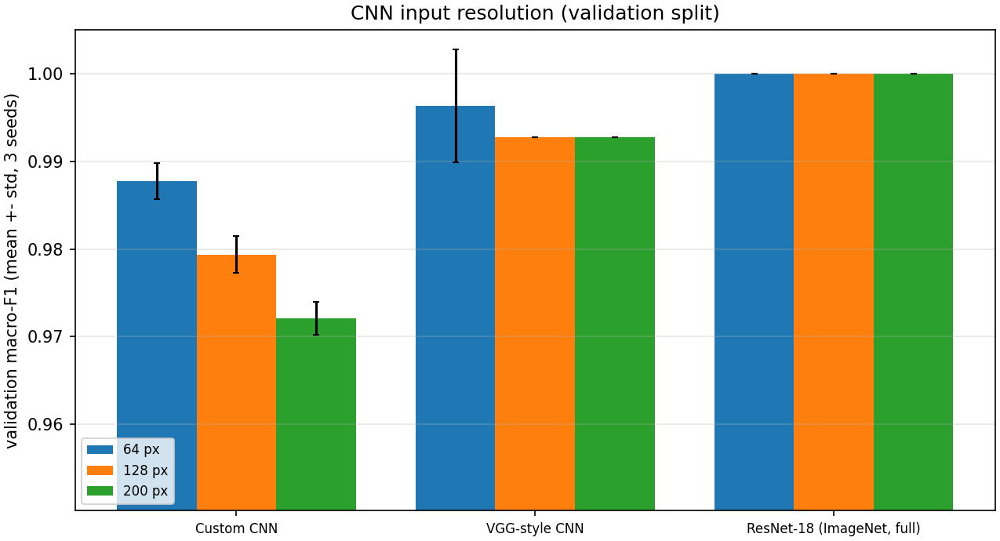

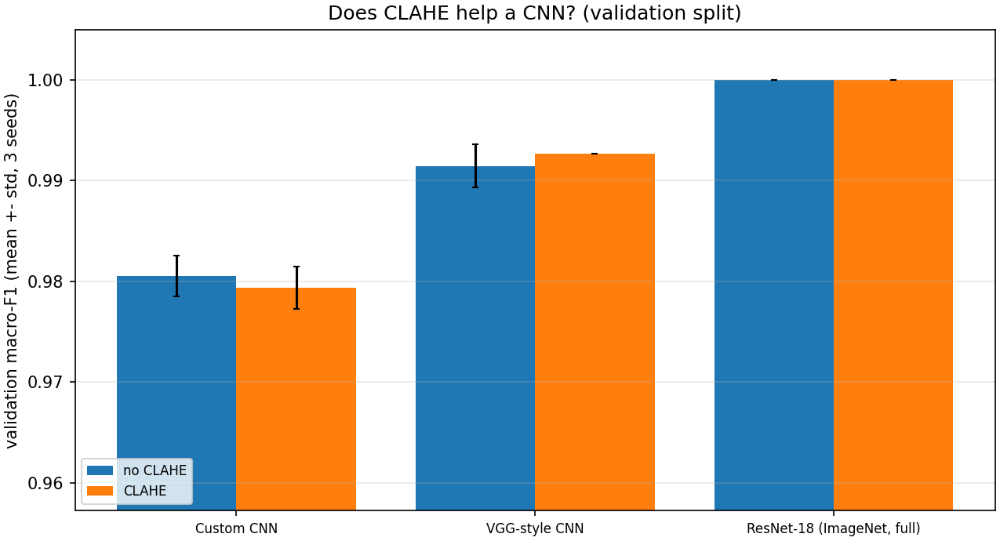

In [7]:
show(FIG / "cnn" / "cnn_resolution.png")
show(FIG / "cnn" / "cnn_clahe.png")

* **The custom CNN gets worse as the resolution grows** (0.9878 at 64 px, 0.9794 at 128 px, 0.9721 at
  200 px): its receptive field is only about 22 pixels. Its 128 px default was never tuned for it;
  the main runs keep it, so this is a finding, not a change made after the fact.
* **VGG is flat**, and ResNet-18 (ImageNet, full) is perfect on validation at every size, so the
  validation split cannot rank its settings.
* **CLAHE does not matter for CNNs** (at most 0.0012, inside the seed spread). With Phase 2: CLAHE is
  within noise for texture features, hurts HOG, and is unnecessary for CNNs.